# Lean variance analysis for `merged.csv`

This notebook is intentionally small: load `merged.csv`, apply the requested preprocessing stub, run train/test-aware statistical tests, plot raw/FDR-corrected p-value distributions, and plot variance explained.


In [1]:
from pathlib import Path
import os
import sys
project_root = Path.cwd() if (Path.cwd() / 'code').is_dir() else Path.cwd().parent
if not (project_root / 'code').is_dir():
    raise RuntimeError('Start Jupyter from the repository root or notebooks/ directory')
os.chdir(project_root)
sys.path.insert(0, str(project_root / 'code'))
import warnings

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["svg.fonttype"] = "none"

DATA_PATH = Path("merged_datasets/merged.csv")
OUT_DIR = Path("figures/variance_analysis")

# Set this to a CSV/TSV/parquet file to read a precomputed variance-explained table.
# Expected columns: dataset, feature or var, factor, var_explained.
VAR_EXPLAINED_PATH = None#Path("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/variance_df_2.csv")
CALCULATE_VARIANCE_EXPLAINED_IF_MISSING = True

SAVE_TABLES = False
SAVE_FIGURES = False

FEATURE_COLUMNS = ["roc", "top_100_pct", "correlation"]
MIN_GROUPS = 3
MIN_POINTS_PER_GROUP = 2
MIN_POINTS_FOR_ANOVA = 5


discretized_parameter_scale = {
    "esm_35m": "0_100",
    "esm_8m": "0_100",
    "esm_150m": "100_500",
    "esm_650m": "500_1000",
    "esm_3b": "500_1000",
    "progen2-small": "100_500",
    "progen2-medium": "500_1000",
    "prot_bert": "100_500",
}


In [2]:
from utils_for_analysis  import plot_exporter

In [3]:
export_plot = plot_exporter("figures/variance_analysis")

## Load and preprocess

Keep this function as the single preprocessing stub for `merged.csv` before analysis.


In [4]:
def preprocess_merged_csv(df):
    """Preprocess merged.csv before any analysis."""
    df = df.copy()

    # Requested filtering stub.
    df = df[~df["model_name"].isin(["one_hot", "linreg"])]
    df = df[df["clf_type"] == "mlp"]
    df["scale"] = df["model_name"].map(discretized_parameter_scale)

    return df.reset_index(drop=True)


raw_df = pd.read_csv(DATA_PATH)
df = preprocess_merged_csv(raw_df)

print(f"raw rows: {len(raw_df):,}")
print(f"preprocessed rows: {len(df):,}")
display(df.head())


raw rows: 2,553
preprocessed rows: 1,896


,roc,clf_type,top_100_pct,test_mutations,train_mutations,dataset,model_name,correlation,scale
0,0.942768,mlp,1.00,6,5,his2,esm_3b,NaN,500_1000
1,0.941512,mlp,1.00,7,5,his2,esm_3b,NaN,500_1000
2,0.938269,mlp,1.00,8,5,his2,esm_3b,NaN,500_1000
3,0.924989,mlp,0.98,9,5,his2,esm_3b,NaN,500_1000
4,0.920326,mlp,0.94,10,5,his2,esm_3b,NaN,500_1000


In [5]:
DATASET_LABELS = {
    "gfp": "GFP",
    "pard3": "PARD3",
    "nmt": "NMT",
    "gcn": "GCN4",
    "gcn4": "GCN4",
    "lov": "LOV",
    "his": "HIS",
    "his2": "HIS2",
    "his5": "HIS5",
    "casp": "CASP",
}

FEATURE_LABELS = {
    "roc": "ROC-AUC",
    "top_100_pct": "Top 100%",
    "correlation": "Correlation",
}


def available_features(sub_df, feature_columns=FEATURE_COLUMNS):
    return [col for col in feature_columns if col in sub_df.columns and sub_df[col].notna().any()]


def display_dataset(value):
    return DATASET_LABELS.get(str(value), str(value).upper())


def display_feature(value):
    return FEATURE_LABELS.get(str(value), str(value).replace("_", " ").title())


def fdr_bh(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    adjusted = np.full(pvalues.shape, np.nan, dtype=float)
    valid = np.isfinite(pvalues)
    if valid.sum() == 0:
        return adjusted

    valid_pvalues = pvalues[valid]
    order = np.argsort(valid_pvalues)
    ranked = valid_pvalues[order]
    n = len(ranked)

    ranked_adjusted = np.empty(n, dtype=float)
    running_min = 1.0
    for i in range(n - 1, -1, -1):
        rank = i + 1
        running_min = min(running_min, ranked[i] * n / rank, 1.0)
        ranked_adjusted[i] = running_min

    restored = np.empty(n, dtype=float)
    restored[order] = ranked_adjusted
    adjusted[valid] = restored
    return adjusted


def add_fdr_by(df, p_col="P_value", group_cols=("analysis",)):
    df = df.copy()
    df["P_value_fdr_bh"] = np.nan
    for _, idx in df.groupby(list(group_cols), dropna=False).groups.items():
        df.loc[idx, "P_value_fdr_bh"] = fdr_bh(df.loc[idx, p_col].to_numpy())
    df["FDR_corrected"] = df["P_value_fdr_bh"]
    return df


In [6]:
import numpy as np
from scipy import stats


def check_anova_assumptions(groups, alpha=0.05):
    """
    Check testable assumptions of one-way ANOVA.

    The function always returns a dictionary with the same keys.
    Untestable results are represented by np.nan or None.
    """
    result = {
        "overall_score": np.nan,
        "status": "untestable",
        "reason": None,
        "normality_score": np.nan,
        "equal_variance_score": np.nan,
        "shapiro_statistic": np.nan,
        "shapiro_p": np.nan,
        "levene_statistic": np.nan,
        "levene_p": np.nan,
        "passes_normality": None,
        "passes_equal_variance": None,
        "group_sizes": [],
        "singleton_groups": 0,
        "residual_df": 0,
        "note": "Independence depends on experimental design and cannot be tested here.",
    }

    groups = [np.asarray(group, dtype=float).ravel() for group in groups]
    groups = [group[np.isfinite(group)] for group in groups]
    groups = [group for group in groups if len(group) > 0]

    result["group_sizes"] = [len(group) for group in groups]
    result["singleton_groups"] = sum(len(group) == 1 for group in groups)

    if len(groups) < 2:
        result["reason"] = "At least two non-empty groups are required."
        return result

    total_n = sum(len(group) for group in groups)
    result["residual_df"] = total_n - len(groups)

    if result["residual_df"] <= 0:
        result["reason"] = (
            "All groups are singletons, so residual variance cannot be estimated."
        )
        return result

    residuals = np.concatenate([group - np.mean(group) for group in groups])

    # Normality of the ANOVA residuals
    if len(residuals) >= 3 and np.std(residuals) > 0:
        if len(residuals) > 5000:
            rng = np.random.default_rng(0)
            tested_residuals = rng.choice(residuals, size=5000, replace=False)
        else:
            tested_residuals = residuals

        shapiro_statistic, shapiro_p = stats.shapiro(tested_residuals)

        result["shapiro_statistic"] = shapiro_statistic
        result["shapiro_p"] = shapiro_p
        result["normality_score"] = min(1.0, shapiro_p / alpha)
        result["passes_normality"] = bool(shapiro_p >= alpha)

    # Singleton groups have no estimable within-group variance, so exclude them
    # from Levene's test.
    replicated_groups = [group for group in groups if len(group) >= 2]

    if len(replicated_groups) >= 2:
        levene_statistic, levene_p = stats.levene(
            *replicated_groups,
            center="median",
        )

        if np.isfinite(levene_p):
            result["levene_statistic"] = levene_statistic
            result["levene_p"] = levene_p
            result["equal_variance_score"] = min(1.0, levene_p / alpha)
            result["passes_equal_variance"] = bool(levene_p >= alpha)

    available_scores = [
        score
        for score in [
            result["normality_score"],
            result["equal_variance_score"],
        ]
        if np.isfinite(score)
    ]

    if available_scores:
        result["overall_score"] = min(available_scores)
        result["status"] = "testable"

        if len(available_scores) == 2:
            result["reason"] = "Both testable assumptions were evaluated."
        else:
            result["reason"] = "Only one assumption could be evaluated."

    else:
        result["reason"] = "Neither assumption could be evaluated reliably."

    return result

## Statistical tests

Train/test logic here means:

- `same_train_mutations_compare_models`: within each dataset and train-mutation count, compare `model_name` groups.
- `same_test_mutations_compare_models`: within each dataset and test-mutation count, compare `model_name` groups.
- `same_test_mutations_compare_train_mutations`: within each dataset and test-mutation count, compare `train_mutations` groups.

The plots below use ANOVA p-values. Kruskal-Wallis results are kept in the output tables for inspection.


In [7]:
def run_group_tests(
    df,
    *,
    comparison_type,
    compare_col,
    fixed_cols,
    feature_columns=FEATURE_COLUMNS,
    min_groups_for_anova=MIN_GROUPS,
    min_points_per_group=MIN_POINTS_PER_GROUP,
    min_points_for_anova=MIN_POINTS_FOR_ANOVA,
    permutation_iterations=1000,
):
    rows = []

    for fixed_values, sub_df in df.groupby(fixed_cols, dropna=False):
        if not isinstance(fixed_values, tuple):
            fixed_values = (fixed_values,)
        fixed = dict(zip(fixed_cols, fixed_values))

        for feature in available_features(sub_df, feature_columns):
            groups = []
            group_names = []
            for group_name, group_df in sub_df.groupby(compare_col, dropna=False):
                values = group_df[feature].dropna().to_numpy(dtype=float)
                if len(values) >= min_points_per_group:
                    groups.append(values)
                    group_names.append(group_name)

            row = {
                "comparison_type": comparison_type,
                "feature": feature,
                "compare_col": compare_col,
                "fixed_cols": ",".join(fixed_cols),
                "n_groups": len(groups),
                "n_points": int(sum(len(g) for g in groups)),
                **fixed,
            }

            f_stat = p_value = k_stat = k_p_value = np.nan
            test_type = None
            nrmlity = check_anova_assumptions(groups)

            if len(groups) > 1 and all(len(group) > 1 for group in groups):
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", stats.ConstantInputWarning)
                    f_stat, p_value = stats.f_oneway(*groups)
                try:
                    k_stat, k_p_value = stats.kruskal(*groups)
                except ValueError:
                    k_stat, k_p_value = np.nan, np.nan

                test_type = "ANOVA"
                if len(groups[0]) < min_points_for_anova or len(groups) < min_groups_for_anova:
                    test_type = "permutation"
                    f_obs = f_stat
                    f_perm = []
                    group_array = np.array(groups)
                    for _ in range(permutation_iterations):
                        permuted_groups = np.random.permutation(group_array)
                        f_stat_perm, _ = stats.f_oneway(*permuted_groups)
                        f_perm.append(f_stat_perm)
                    p_value = 1 - np.sum(np.sort(np.array([f_perm]) <= f_obs)) / len(f_perm)
                    k_p_value = np.nan

            row.update({
                "test_type": test_type,
                "F_value": f_stat,
                "P_value": p_value,
                "Kruskal_H": k_stat,
                "Kruskal_P": k_p_value,
                "groups": ",".join(map(str, group_names)),
            })
            row.update(nrmlity)
            rows.append(row)

    return pd.DataFrame(rows)


In [8]:
model_pvalue_df = pd.concat(
    [
        run_group_tests(
            df,
            comparison_type="train",
            compare_col="model_name",
            fixed_cols=["dataset", "train_mutations"],
        ),
        run_group_tests(
            df,
            comparison_type="test",
            compare_col="model_name",
            fixed_cols=["dataset", "test_mutations"],
        ),
    ],
    ignore_index=True,
)


In [9]:
model_pvalue_df.columns

Index(['comparison_type', 'feature', 'compare_col', 'fixed_cols', 'n_groups',
       'n_points', 'dataset', 'train_mutations', 'test_type', 'F_value',
       'P_value', 'Kruskal_H', 'Kruskal_P', 'groups', 'overall_score',
       'status', 'reason', 'normality_score', 'equal_variance_score',
       'shapiro_statistic', 'shapiro_p', 'levene_statistic', 'levene_p',
       'passes_normality', 'passes_equal_variance', 'group_sizes',
       'singleton_groups', 'residual_df', 'note', 'test_mutations'],
      dtype='object')

In [10]:
model_pvalue_df["final_pvalue"] = model_pvalue_df["P_value"]
# non_anova_ind = model_pvalue_df["passes_normality"].to_numpy() != False
# model_pvalue_df[non_anova_ind]["final_pvalue"] = model_pvalue_df[non_anova_ind]["Kruskal_P"]

In [11]:
model_pvalue_df = add_fdr_by(model_pvalue_df, group_cols=("comparison_type",), p_col="P_value")

train_mutation_pvalue_df = run_group_tests(
    df,
    comparison_type="test",
    compare_col="train_mutations",
    fixed_cols=["dataset", "test_mutations"],
)

# train_mutation_pvalue_df["final_pvalue"] = train_mutation_pvalue_df["P_value"]
# non_anova_ind = train_mutation_pvalue_df["passes_normality"].to_numpy() != False
# train_mutation_pvalue_df[non_anova_ind]["final_pvalue"] = train_mutation_pvalue_df[non_anova_ind]["Kruskal_P"]

train_mutation_pvalue_df = add_fdr_by(train_mutation_pvalue_df, group_cols=("comparison_type",), p_col="P_value")

if SAVE_TABLES:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    model_pvalue_df.to_csv(OUT_DIR / "merged_model_comparison_pvalues.csv", index=False)
    train_mutation_pvalue_df.to_csv(OUT_DIR / "merged_train_mutation_comparison_pvalues.csv", index=False)

print("model-comparison tests:", model_pvalue_df["P_value"].notna().sum(), "valid p-values")
print("train-mutation tests:", train_mutation_pvalue_df["P_value"].notna().sum(), "valid p-values")
display(model_pvalue_df.head())
display(train_mutation_pvalue_df.head())


model-comparison tests: 132 valid p-values
train-mutation tests: 78 valid p-values


,comparison_type,feature,compare_col,fixed_cols,n_groups,n_points,dataset,train_mutations,test_type,F_value,...,passes_normality,passes_equal_variance,group_sizes,singleton_groups,residual_df,note,test_mutations,final_pvalue,P_value_fdr_bh,FDR_corrected
0,train,correlation,model_name,"dataset,train_mutations",8,72,casp,1.0,ANOVA,1.777798,...,False,True,"[9, 9, 9, 9, 9, 9, 9, 9]",0,64,Independence depends on experimental design an...,NaN,0.107180,0.385847,0.385847
1,train,correlation,model_name,"dataset,train_mutations",8,64,casp,2.0,ANOVA,0.361074,...,True,True,"[8, 8, 8, 8, 8, 8, 8, 8]",0,56,Independence depends on experimental design an...,NaN,0.920900,0.999999,0.999999
2,train,correlation,model_name,"dataset,train_mutations",8,56,casp,3.0,ANOVA,1.174111,...,False,True,"[7, 7, 7, 7, 7, 7, 7, 7]",0,48,Independence depends on experimental design an...,NaN,0.335208,0.979568,0.979568
3,train,correlation,model_name,"dataset,train_mutations",8,48,casp,4.0,ANOVA,0.560916,...,False,True,"[6, 6, 6, 6, 6, 6, 6, 6]",0,40,Independence depends on experimental design an...,NaN,0.782815,0.999999,0.999999
4,train,correlation,model_name,"dataset,train_mutations",8,40,casp,5.0,ANOVA,0.595634,...,False,True,"[5, 5, 5, 5, 5, 5, 5, 5]",0,32,Independence depends on experimental design an...,NaN,0.754623,0.999999,0.999999


,comparison_type,feature,compare_col,fixed_cols,n_groups,n_points,dataset,test_mutations,test_type,F_value,...,levene_statistic,levene_p,passes_normality,passes_equal_variance,group_sizes,singleton_groups,residual_df,note,P_value_fdr_bh,FDR_corrected
0,test,correlation,train_mutations,"dataset,test_mutations",1,8,casp,2,None,NaN,...,NaN,NaN,None,None,[8],0,0,Independence depends on experimental design an...,NaN,NaN
1,test,correlation,train_mutations,"dataset,test_mutations",2,16,casp,3,permutation,3038.279737,...,0.647066,0.434612,False,True,"[8, 8]",0,14,Independence depends on experimental design an...,0.000000e+00,0.000000e+00
2,test,correlation,train_mutations,"dataset,test_mutations",3,24,casp,4,ANOVA,1170.277274,...,0.638268,0.538149,True,True,"[8, 8, 8]",0,21,Independence depends on experimental design an...,7.335956e-22,7.335956e-22
3,test,correlation,train_mutations,"dataset,test_mutations",4,32,casp,5,ANOVA,537.482824,...,2.497717,0.080156,True,True,"[8, 8, 8, 8]",0,28,Independence depends on experimental design an...,3.513798e-24,3.513798e-24
4,test,correlation,train_mutations,"dataset,test_mutations",5,40,casp,6,ANOVA,220.807598,...,1.779409,0.155053,True,True,"[8, 8, 8, 8, 8]",0,35,Independence depends on experimental design an...,1.027601e-23,1.027601e-23


## P-value distributions

In [12]:
def make_pvalue_plot_df(pvalue_df, *, p_col="FDR_corrected", comparison_types=("all", "test", "train")):
    rows = []
    work_df = pvalue_df.copy()
    work_df["dataset_label"] = work_df["dataset"].map(display_dataset)

    combo = work_df[["feature", "dataset", "dataset_label"]].drop_duplicates()
    plot_order = combo.apply(lambda r: f"{r['feature']}\n{r['dataset_label']}", axis=1).tolist()
    plot_labels = combo.apply(lambda r: f"{r['dataset_label']}\n({display_feature(r['feature'])})", axis=1).tolist()

    for fd, pretty_label in zip(plot_order, plot_labels):
        feature, dataset_label = fd.split("\n", 1)
        base_mask = (work_df["feature"] == feature) & (work_df["dataset_label"] == dataset_label)
        for comp_type in comparison_types:
            if comp_type == "all":
                mask = base_mask
            else:
                mask = base_mask & (work_df["comparison_type"] == comp_type)
            for _, row in work_df.loc[mask].iterrows():
                test_type = row.get("test_type")
                rows.append({
                    "feature_dataset": fd,
                    "feature_dataset_y": pretty_label,
                    "comparison_type": comp_type,
                    "P_value": row[p_col],
                    "test_type": test_type.lower() if isinstance(test_type, str) else None,
                })

    plot_df = pd.DataFrame(rows)
    if len(plot_df):
        plot_df = plot_df[plot_df["comparison_type"].isin(comparison_types)]
        plot_df = plot_df[plot_df["feature_dataset"].isin(plot_order)]
    return plot_df, plot_order, plot_labels


def plot_pvalue_summary(
    pvalue_df,
    *,
    p_col="FDR_corrected",
    comparison_types=("all", "test", "train"),
    output_name=None,
    figsize=(8, 4),
):
    plot_df, plot_order, plot_labels = make_pvalue_plot_df(
        pvalue_df,
        p_col=p_col,
        comparison_types=comparison_types,
    )
    if plot_df.empty:
        print("No p-values to plot.")
        return None

    summary = (
        plot_df.groupby(["feature_dataset", "comparison_type"])["P_value"]
        .agg(["mean", "std"])
        .reset_index()
    )

    color_values = plt.get_cmap("Set1")(np.linspace(0, 1, max(3, len(comparison_types))))
    color_map = dict(zip(comparison_types, color_values))
    width = 0.25
    if len(comparison_types) == 1:
        dodge_pos = {comparison_types[0]: 0.0}
    else:
        dodge_pos = dict(zip(comparison_types, np.linspace(-width, width, len(comparison_types))))

    rng = np.random.default_rng(1)
    fig, ax = plt.subplots(figsize=figsize)

    for i, fd in enumerate(plot_order):
        for comp_type in comparison_types:
            sub = summary[(summary["feature_dataset"] == fd) & (summary["comparison_type"] == comp_type)]
            if sub.empty:
                continue
            mean = sub["mean"].iloc[0]
            std = sub["std"].iloc[0]
            ax.errorbar(
                i + dodge_pos[comp_type],
                mean,
                yerr=0.0 if pd.isna(std) else std,
                fmt="o",
                markersize=8,
                color=color_map[comp_type],
                elinewidth=2,
                capsize=1,
                alpha=0.7,
                markeredgewidth=0,
                zorder=4,
            )

    marker_dict = {"anova": "o", "permutation": "s", None: "o"}
    label_dict = {"anova": "ANOVA/KW", "permutation": "Permutation"}
    seen_test_types = set()

    for i, fd in enumerate(plot_order):
        for comp_type in comparison_types:
            pts = plot_df[(plot_df["feature_dataset"] == fd) & (plot_df["comparison_type"] == comp_type)]
            for test_type, pts_tt in pts.groupby("test_type", dropna=False):
                marker = marker_dict.get(test_type, "o")
                x = i + dodge_pos[comp_type] + rng.uniform(-0.09, 0.09, len(pts_tt))
                ax.scatter(
                    x,
                    pts_tt["P_value"].to_numpy(),
                    s=45,
                    marker=marker,
                    color="black",
                    alpha=0.85,
                    linewidth=0.7,
                    edgecolors="black",
                    zorder=3,
                )
                seen_test_types.add(test_type)

    from matplotlib.lines import Line2D

    comp_handles = [
        Line2D([0], [0], marker="o", color="w", markerfacecolor=color_map[c], markersize=8, linestyle="None", label=c)
        for c in comparison_types
    ]
    test_handles = [
        Line2D([0], [0], marker=marker_dict[t], color="black", markerfacecolor="black", markersize=8, linestyle="None", label=label_dict[t])
        for t in ("anova", "permutation")
        if t in seen_test_types
    ]

    ax.grid(True, which="major", linestyle="--", linewidth=0.25, alpha=0.7)
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.set_xticks(range(len(plot_order)))
    ax.set_xticklabels(plot_labels, rotation=30, ha="right")
    ax.set_ylabel("P-value (Corrected)" if p_col == "FDR_corrected" else "P-value")
    ax.set_xlabel("")
    ax.axhline(0.05, color="black", linestyle="--", lw=1)
    ax.legend(handles=comp_handles + test_handles, title="Comparison / Test Type", loc="best")
    fig.tight_layout()

    if SAVE_FIGURES and output_name is not None:
        OUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUT_DIR / output_name, format="svg", bbox_inches="tight")

    return fig


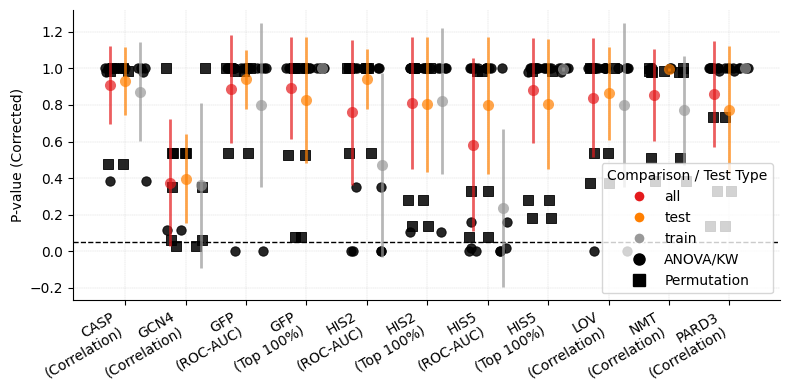

In [13]:
fig = plot_pvalue_summary(
    model_pvalue_df,
    p_col="FDR_corrected",
    comparison_types=("all", "test", "train"),
    #output_name="pvalue_dist_corrected_fdr_new.svg",
)

export_plot("pvalue_dist_fdr_correction", fig=fig)

plt.show()


In [14]:
model_pvalue_df

,comparison_type,feature,compare_col,fixed_cols,n_groups,n_points,dataset,train_mutations,test_type,F_value,...,passes_normality,passes_equal_variance,group_sizes,singleton_groups,residual_df,note,test_mutations,final_pvalue,P_value_fdr_bh,FDR_corrected
0,train,correlation,model_name,"dataset,train_mutations",8,72,casp,1.0,ANOVA,1.777798,...,False,True,"[9, 9, 9, 9, 9, 9, 9, 9]",0,64,Independence depends on experimental design an...,NaN,0.107180,0.385847,0.385847
1,train,correlation,model_name,"dataset,train_mutations",8,64,casp,2.0,ANOVA,0.361074,...,True,True,"[8, 8, 8, 8, 8, 8, 8, 8]",0,56,Independence depends on experimental design an...,NaN,0.920900,0.999999,0.999999
2,train,correlation,model_name,"dataset,train_mutations",8,56,casp,3.0,ANOVA,1.174111,...,False,True,"[7, 7, 7, 7, 7, 7, 7, 7]",0,48,Independence depends on experimental design an...,NaN,0.335208,0.979568,0.979568
3,train,correlation,model_name,"dataset,train_mutations",8,48,casp,4.0,ANOVA,0.560916,...,False,True,"[6, 6, 6, 6, 6, 6, 6, 6]",0,40,Independence depends on experimental design an...,NaN,0.782815,0.999999,0.999999
4,train,correlation,model_name,"dataset,train_mutations",8,40,casp,5.0,ANOVA,0.595634,...,False,True,"[5, 5, 5, 5, 5, 5, 5, 5]",0,32,Independence depends on experimental design an...,NaN,0.754623,0.999999,0.999999
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
138,test,correlation,model_name,"dataset,test_mutations",8,40,pard3,NaN,ANOVA,1.072092,...,True,True,"[5, 5, 5, 5, 5, 5, 5, 5]",0,32,Independence depends on experimental design an...,6.0,0.403540,0.999981,0.999981
139,test,correlation,model_name,"dataset,test_mutations",8,40,pard3,NaN,ANOVA,0.243108,...,True,True,"[5, 5, 5, 5, 5, 5, 5, 5]",0,32,Independence depends on experimental design an...,7.0,0.970814,0.999981,0.999981
140,test,correlation,model_name,"dataset,test_mutations",8,40,pard3,NaN,ANOVA,0.495375,...,True,True,"[5, 5, 5, 5, 5, 5, 5, 5]",0,32,Independence depends on experimental design an...,8.0,0.830788,0.999981,0.999981
141,test,correlation,model_name,"dataset,test_mutations",8,40,pard3,NaN,ANOVA,0.360686,...,True,True,"[5, 5, 5, 5, 5, 5, 5, 5]",0,32,Independence depends on experimental design an...,9.0,0.918218,0.999981,0.999981


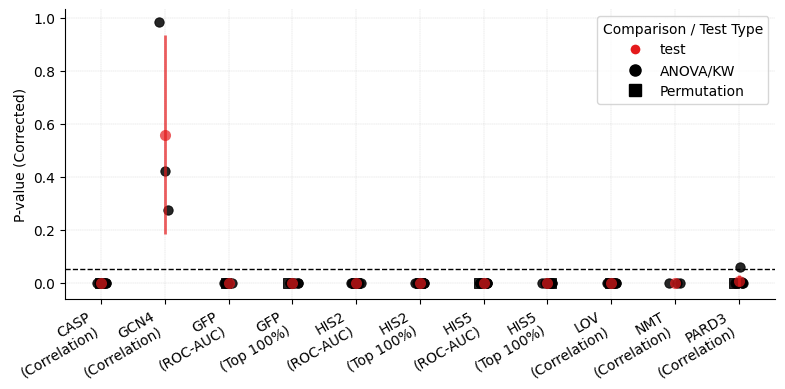

In [15]:
plot_pvalue_summary(
    train_mutation_pvalue_df,
    p_col="FDR_corrected",
    comparison_types=("test",),
    output_name="pvalue_dist_corrected_fdr_new_train_as_factor.svg",
)
plt.show()


## Cumulative p-value distributions

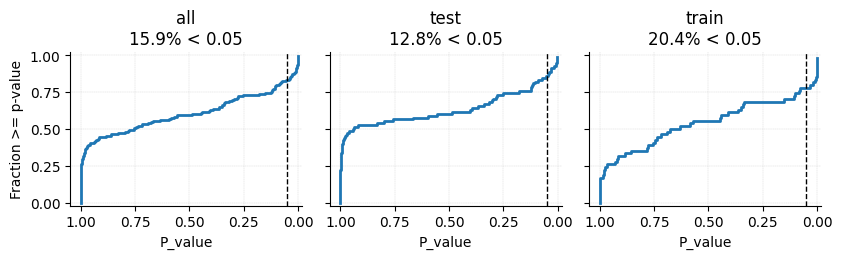

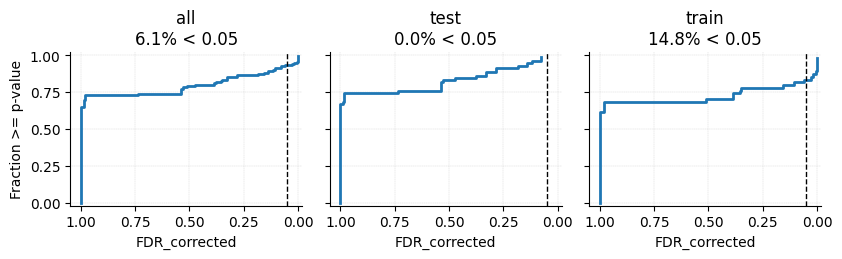

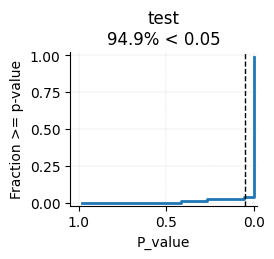

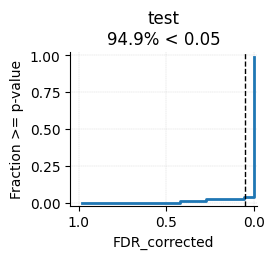

In [16]:
def plot_pvalue_cdf(pvalue_df, p_col, *, comparison_types=("all", "test", "train"), output_name=None):
    fig, axes = plt.subplots(1, len(comparison_types), figsize=(2.8 * len(comparison_types), 2.7), sharey=True)
    if len(comparison_types) == 1:
        axes = [axes]

    for ax, comp_type in zip(axes, comparison_types):
        if comp_type == "all":
            values = pvalue_df[p_col]
        else:
            values = pvalue_df.loc[pvalue_df["comparison_type"] == comp_type, p_col]

        pvalues = values.dropna().sort_values().to_numpy()
        if len(pvalues):
            cumulative = 1 - np.arange(1, len(pvalues) + 1) / len(pvalues)
            significant = 100 * np.mean(pvalues < 0.05)
            ax.step(pvalues[::-1], cumulative[::-1], where="post", lw=2)
            ax.set_title(f"{comp_type}\n{significant:.1f}% < 0.05")
        else:
            ax.set_title(f"{comp_type}\nno p-values")

        ax.axvline(0.05, color="black", linestyle="--", lw=1)
        ax.set_xlim(1.05, -0.02)
        ax.set_ylim(-0.02, 1.02)
        ax.set_xlabel(p_col)
        ax.grid(True, linestyle="--", linewidth=0.25, alpha=0.7)
        ax.spines["right"].set_visible(False)
        ax.spines["top"].set_visible(False)

    axes[0].set_ylabel("Fraction >= p-value")
    fig.tight_layout()

    if SAVE_FIGURES and output_name is not None:
        OUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUT_DIR / output_name, format="svg", bbox_inches="tight")

    return fig


plot_pvalue_cdf(
    model_pvalue_df,
    "P_value",
    comparison_types=("all", "test", "train"),
    output_name="pvalue_fractions_new.svg",
)
corrected_all = plot_pvalue_cdf(
    model_pvalue_df,
    "FDR_corrected",
    comparison_types=("all", "test", "train"),
    output_name="pvalue_fractions_corrected_fdr_new.svg",
)


export_plot("corrected_all", fig=corrected_all)


plt.show()


plot_pvalue_cdf(
    train_mutation_pvalue_df,
    "P_value",
    comparison_types=("test",),
    output_name="by_train_mutations_pvalue_fractions_new.svg",
)
corrected_muts = plot_pvalue_cdf(
    train_mutation_pvalue_df,
    "FDR_corrected",
    comparison_types=("test",),
    output_name="by_train_mutations_pvalue_fractions_corrected_fdr_new.svg"
)
export_plot("corrected_muts", fig=corrected_muts)

plt.show()


## F-value distribution

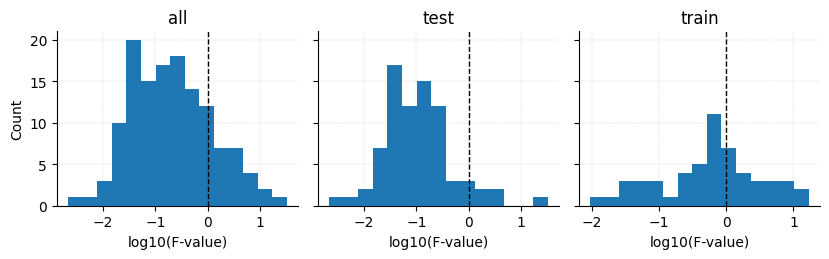

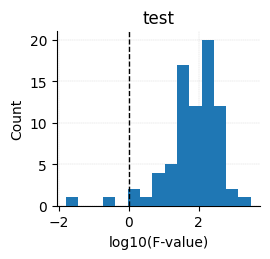

In [17]:
def plot_fvalue_distribution(pvalue_df, *, comparison_types=("all", "test", "train"), output_name=None):
    fig, axes = plt.subplots(1, len(comparison_types), figsize=(2.8 * len(comparison_types), 2.7), sharey=True)
    if len(comparison_types) == 1:
        axes = [axes]

    for ax, comp_type in zip(axes, comparison_types):
        if comp_type == "all":
            values = pvalue_df["F_value"]
        else:
            values = pvalue_df.loc[pvalue_df["comparison_type"] == comp_type, "F_value"]

        log_values = np.log10(values.replace([np.inf, -np.inf], np.nan).dropna())
        log_values = log_values[np.isfinite(log_values)]
        if len(log_values):
            ax.hist(log_values, bins=15, zorder=3)
        ax.axvline(0, color="black", linestyle="--", lw=1, zorder=4)
        ax.set_title(comp_type)
        ax.set_xlabel("log10(F-value)")
        ax.grid(True, which="major", linestyle="--", linewidth=0.25, alpha=0.7, zorder=2)
        ax.spines["right"].set_visible(False)
        ax.spines["top"].set_visible(False)

    axes[0].set_ylabel("Count")
    fig.tight_layout()

    if SAVE_FIGURES and output_name is not None:
        OUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUT_DIR / output_name, format="svg", bbox_inches="tight")

    return fig


fval_all = plot_fvalue_distribution(
    model_pvalue_df,
    comparison_types=("all", "test", "train"),
    output_name="f_value_distribution_new.svg",
)
export_plot("fval_all", fig=fval_all)
fval_muts = plot_fvalue_distribution(
    train_mutation_pvalue_df,
    comparison_types=("test",),
    output_name="f_value_distribution_train_as_factor.svg",
)

export_plot("fval_muts", fig=fval_muts)
plt.show()


## Variance explained

By default this calculates a lean one-way eta-squared value (`SS_factor / SS_total`) independently inside each dataset/test-mutation regime. `test_mutations` is recorded as the regime, not used as a factor. To read an existing table instead, set `VAR_EXPLAINED_PATH` in the config cell.


In [18]:
def read_table(path):
    path = Path(path).expanduser()
    if path.suffix == ".parquet":
        return pd.read_parquet(path)
    if path.suffix in {".tsv", ".tab"}:
        return pd.read_csv(path, sep="	")
    return pd.read_csv(path)


def one_way_variance_explained(sub_df, feature, factor):
    values = sub_df[[feature, factor]].dropna()
    if values[feature].nunique() <= 1 or values[factor].nunique() <= 1:
        return np.nan

    y = values[feature].to_numpy(dtype=float)
    overall_mean = y.mean()
    total_ss = np.sum((y - overall_mean) ** 2)
    if total_ss == 0:
        return np.nan

    grouped = values.groupby(factor)[feature].agg(["mean", "count"])
    factor_ss = np.sum(grouped["count"] * (grouped["mean"] - overall_mean) ** 2)
    return factor_ss / total_ss


def calculate_variance_explained(df, factors=("model_name", "train_mutations", "budget", "scale")):
    rows = []
    factors = [factor for factor in factors if factor in df.columns]

    for (dataset, test_mutations), regime_df in df.groupby(["dataset", "test_mutations"]):
        for feature in available_features(regime_df):
            for factor in factors:
                rows.append({
                    "dataset": dataset,
                    "test_mutations": test_mutations,
                    "feature": feature,
                    "factor": factor,
                    "var_explained": one_way_variance_explained(regime_df, feature, factor),
                })
    return pd.DataFrame(rows)


def load_or_calculate_variance_explained():
    if VAR_EXPLAINED_PATH is not None:
        var_df = read_table(VAR_EXPLAINED_PATH)
    elif CALCULATE_VARIANCE_EXPLAINED_IF_MISSING:
        var_df = calculate_variance_explained(df)
    else:
        return pd.DataFrame()

    var_df = var_df.rename(columns={"var": "feature"}).copy()
    required = {"dataset", "feature", "factor", "var_explained"}
    missing = required - set(var_df.columns)
    if missing:
        raise ValueError(f"variance-explained table is missing columns: {sorted(missing)}")
    return var_df


var_explained_df = load_or_calculate_variance_explained()

if SAVE_TABLES and len(var_explained_df):
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    var_explained_df.to_csv(OUT_DIR / "merged_variance_explained.csv", index=False)

display(var_explained_df)


,dataset,test_mutations,feature,factor,var_explained
0,casp,2,correlation,model_name,1.000000
1,casp,2,correlation,train_mutations,NaN
2,casp,2,correlation,scale,0.178157
3,casp,3,correlation,model_name,0.001840
4,casp,3,correlation,train_mutations,0.995413
...,...,...,...,...,...
256,pard3,9,correlation,train_mutations,0.713235
257,pard3,9,correlation,scale,0.022427
258,pard3,10,correlation,model_name,0.221589
259,pard3,10,correlation,train_mutations,0.392950


In [19]:
# var_explained_df[var_explained_df["dataset"] == "his5"]

# ovd = pd.read_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/variance_df.csv")

In [20]:
# ovd = ovd.drop(columns=["Unnamed: 0"], errors="ignore")


# new_ovd =\
# pd.concat([
#     var_explained_df[var_explained_df["dataset"].isin(["his2", "his5"])],
#     ovd[~ovd["dataset"].isin(["his2", "his5"])]
# ])

# new_ovd.to_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/variance_final_df.csv",index=False)



In [21]:
# ovd[ovd["dataset"].isin(["his2", "his5"])]
# var_explained_df[var_explained_df["dataset"].isin(["his2", "his5"])]

In [24]:
new_ovd = pd.read_csv("merged_datasets/variance_final_df.csv")

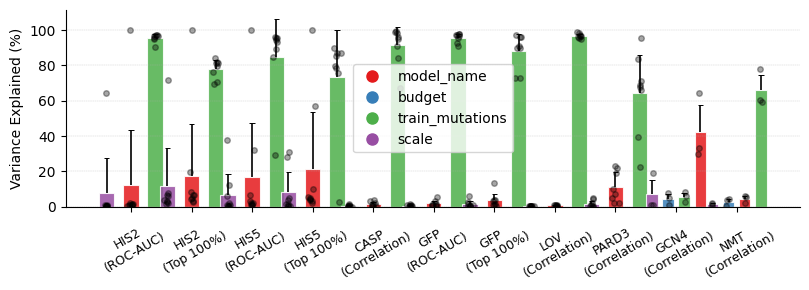

In [25]:
def plot_variance_explained(var_df, output_name="variance_explained_by_factor_barplot.svg"):
    if var_df.empty:
        print("No variance-explained data to plot.")
        return None

    # Match the original plotting dataframe shape.
    df_var_all = var_df.rename(columns={"feature": "var"}).copy()
    if "y_label" not in df_var_all.columns:
        df_var_all["y_label"] = df_var_all["var"].map(display_feature)

    # Assume df_var_all is already loaded
    df = df_var_all.copy()

    # Multiply variance explained by 100 to get percent
    df["var_explained"] = df["var_explained"] * 100

    # Build unique var-dataset combos
    combo = df[["var", "dataset"]].drop_duplicates().reset_index(drop=True)
    combo["var_dataset"] = combo.apply(lambda r: f"{r['var']}\n{r['dataset']}", axis=1)
    df = df.merge(combo, on=["var", "dataset"], how="left")

    # Prepare x-label order and pretty y-labels
    feature_dataset_order = combo["var_dataset"].tolist()
    combo_y_label = combo.merge(df[["var", "dataset", "y_label"]].drop_duplicates(), on=["var", "dataset"], how="left")
    feature_dataset_order_y_label = combo_y_label.apply(lambda row: f"{display_dataset(row['dataset'])}\n({row['y_label']})", axis=1).tolist()

    # Define all known factor types
    all_possible_factors = ["model_name", "budget", "train_mutations", "scale"]
    factor_colors = sns.color_palette('Set1', n_colors=len(all_possible_factors))
    factor_color_map = dict(zip(all_possible_factors, factor_colors))

    # For each var_dataset combo, get sorted factor order by median var_explained (smallest-to-largest)
    factor_orders_per_combo = {}
    for vds in feature_dataset_order:
        _df = df[df["var_dataset"] == vds]
        factor_medians = {
            factor: _df.loc[_df["factor"] == factor, "var_explained"].median()
            for factor in _df["factor"].unique()
        }
        # Sort factors for this combo by median
        ordered_factors = sorted(factor_medians, key=lambda k: (factor_medians[k], k))
        factor_orders_per_combo[vds] = ordered_factors

    # Set up canvas for barplot version
    fig, ax = plt.subplots(figsize=(8.2, 3))

    bar_width = 0.8  # total width for all bars at each var_dataset
    scatter_alpha = 0.35
    center_median_marker_size = 40
    errorbar_linewidth = 1.2

    # X locations are integer-aligned by var_dataset
    x_ticks = np.arange(len(feature_dataset_order))

    for x_pos, vds in enumerate(feature_dataset_order):
        vdf = df[df["var_dataset"] == vds].copy()
        factors = factor_orders_per_combo[vds]
        n_factors = len(factors)
        # Bar midpoints for factors (centered about x integer position)
        offset_vec = np.linspace(-bar_width/2, bar_width/2, n_factors)

        for i, (factor, off) in enumerate(zip(factors, offset_vec)):
            sub = vdf[vdf["factor"] == factor]
            vals = sub["var_explained"].dropna().values
            _color = factor_color_map.get(factor, "gray")

            if len(vals) > 0:
                mean = np.mean(vals)
                std = np.std(vals)
                bar_x = x_pos + off

                # Plot bar up to mean
                ax.bar(bar_x, mean,
                       width=bar_width / n_factors * 0.95,
                       color=_color,
                       alpha=0.85,
                       zorder=1,
                       edgecolor="white",
                       linewidth=0.8)

                # Plot error bar: only +std as a thin black line, starting at mean
                # We plot a vertical black line from mean to mean+std if std > 0
                if std > 0:
                    ax.vlines(bar_x, mean, mean + std, colors='black', linestyles='-', lw=errorbar_linewidth, zorder=3)
                    # Optionally a small cap at the top
                    ax.hlines(mean + std, bar_x - 0.045, bar_x + 0.045, colors='black', lw=0.7, zorder=3)

                # Jitter actual points around the center of this bar
                jx = np.random.normal(loc=bar_x, scale=(bar_width / n_factors)*0.10, size=len(vals))
                ax.scatter(jx, vals, color="black", alpha=scatter_alpha, s=16, zorder=4)

                # Overlay median value in black, centered
                # median = np.median(vals)
                # ax.scatter([bar_x], [median], color="black", s=center_median_marker_size, zorder=5,
                #            marker="o", edgecolor="white", linewidth=0.7)

    # X ticks: one per var_dataset, pretty label
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(feature_dataset_order_y_label, rotation=30, fontsize=9)

    # Prepare ordered legend as in plot, without duplicates
    seen = set()
    legend_handles = []
    legend_labels = []
    for f in all_possible_factors:
        if any(f in factor_orders_per_combo[vds] for vds in feature_dataset_order) and f not in seen:
            seen.add(f)
            color = factor_color_map.get(f, "gray")
            h = plt.Line2D([0], [0], color=color, marker="o", linestyle="", markersize=8, label=f)
            legend_handles.append(h)
            legend_labels.append(f)
    ax.legend(legend_handles, legend_labels)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_ylabel("Variance Explained (%)")
    ax.set_xlabel("")
    ax.grid(True, axis='y', linestyle='--', linewidth=0.3, alpha=0.7)
    plt.tight_layout()

    if SAVE_FIGURES:
        OUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUT_DIR / output_name, format='svg', bbox_inches="tight")

    return fig


fig = plot_variance_explained(new_ovd)
export_plot("var_explained_plot", fig=fig)
plt.show()
